<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/02_RegresionLineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión Lineal

## 1. Librerias y configuraciones previas


In [31]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np

# Preprocesado y modelado
# ==============================================================================
from statsmodels import api as sm
#from sklearn.linear_model import LinearRegression  # alternativa con scikit-learn (ver sección 4); aquí se usa statsmodels
from sklearn.model_selection import train_test_split

#Evaluación del modelo
# ==============================================================================
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, median_absolute_error

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Interactuar con el sistema operativo y solicitudes HTTP
# ==============================================================================
import os
import sys
import requests
from urllib.parse import urljoin

# Configuración warnings
# ==============================================================================
import warnings
# Se ocultan solo los avisos informativos de versiones; los demás avisos siguen visibles
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
# Aviso de matplotlib que genera internamente sm.qqplot al personalizar el color de los puntos (no afecta el resultado)
warnings.filterwarnings('ignore', message='.*redundantly defined by the')

In [32]:
# Parametros globales
# ==============================================================================

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME = '01_carDetailsV4_Prep.csv'
UTILS_FILE_NAME = 'funciones.py'

# Nombres de los directorios para utilidades y datasets
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'

# URL completa del dataset y utils en GitHub (urljoin evita errores con las barras)
github_dataset_url = urljoin(GITHUB_BASE_URL, DATASETS_PATH + DATASET_FILE_NAME)
github_utils_url = urljoin(GITHUB_BASE_URL, UTILS_PATH + UTILS_FILE_NAME)

# Rutas locales completas de datasets y utils
local_dataset_path = os.path.join(DATASETS_PATH, DATASET_FILE_NAME)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)

### (Opcional) Cargar datos desde Google Drive

La celda siguiente muestra una **alternativa** para trabajar con archivos guardados en Google Drive, en vez de descargarlos desde GitHub. Se deja comentada porque en este notebook usamos la descarga directa desde el repositorio (más fácil de reproducir para cualquier estudiante), pero queda como referencia por si prefieres montar tu propio Drive.

In [33]:
## Cargar datos desde Google drive
## ==============================================================================

#from google.colab import drive

#drive.mount('/gdrive')

#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

#!ls

In [34]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description, force=False, timeout=30):
    '''
    Descarga un archivo desde una URL y lo guarda localmente en un path.
    Si el archivo ya existe no se vuelve a descargar (usar force=True para obligarlo).

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
        force (bool): Si es True, descarga aunque el archivo ya exista
        timeout (int): Segundos máximos de espera de la descarga
    Returns:
        None
    '''
    if os.path.exists(path) and not force:
        print(f"{description} ya existe en: {path} (no se vuelve a descargar)")
        return

    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url, timeout=timeout)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [35]:
# Configuración entorno Colab
# ==============================================================================

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url, local_dataset_path, "dataset")
download_file(github_utils_url, local_utils_path, "funciones")

dataset ya existe en: datasets/01_carDetailsV4_Prep.csv (no se vuelve a descargar)
funciones ya existe en: utils/funciones.py (no se vuelve a descargar)


## 2. Funciones

En esta sección se define la función `f`, que se usa más adelante para graficar la recta del modelo. Este notebook no necesita funciones de `funciones.py`; por eso solo se deja configurada la ruta `utils/`.

In [36]:
# Funciones externas
# ==============================================================================

# Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

In [37]:
#Funcion Lineal: dado una pendiente 'm', un valor x, y un coeficiente 'b', retorna el valor de 'y'

def f(m, x, b):
    return (m*x)+b

## 3. Carga del dataset

In [38]:
#Se crea un dataframe d con los datos obtenidos de archivo de entrada
d = pd.read_csv(local_dataset_path)

In [39]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               1436 non-null   float64
 1   Year                1436 non-null   int64  
 2   Kilometer           1436 non-null   int64  
 3   Engine              1436 non-null   float64
 4   Length              1436 non-null   float64
 5   Width               1436 non-null   float64
 6   Height              1436 non-null   float64
 7   Seating Capacity    1436 non-null   float64
 8   Fuel Tank Capacity  1436 non-null   float64
 9   Fuel Type           1436 non-null   object 
 10  Transmission        1436 non-null   object 
 11  Owner               1436 non-null   object 
 12  Seller Type         1436 non-null   object 
 13  Drivetrain          1436 non-null   object 
 14  PriceRange          1436 non-null   int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 168.4+

In [40]:
d.head()

,Price,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,Fuel Type,Transmission,Owner,Seller Type,Drivetrain,PriceRange
0,9300.00,2020,39000,1197.00,3995.00,1775.00,1505.00,5.00,37.00,Petrol,Manual,First,Individual,FWD,0
1,7500.00,2019,31000,1197.00,3985.00,1734.00,1505.00,5.00,45.00,Petrol,Manual,First,Individual,FWD,0
2,33600.00,2018,20000,2143.00,4630.00,1777.00,1432.00,5.00,56.00,Diesel,Automatic,First,Individual,FWD,3
3,11939.99,2016,105000,2179.00,4585.00,1890.00,1785.00,7.00,70.00,Diesel,Automatic,Second,Individual,FWD,1
4,18240.00,2021,14000,1997.00,3985.00,1820.00,1844.00,4.00,57.00,Petrol,Manual,First,Individual,AWD,1


## 4. Creación del modelo

### Dividir el conjunto de datos

In [41]:
#Se establece la variable de entrada 'X' y la variable de salida 'y'

X = d[['Engine']]
y = d['Price']

In [42]:
# División de los datos en train y test

#En este caso, el 70% de los datos se utilizarán para entrenar el modelo.

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.7,
                                        random_state = 1234,
                                        shuffle      = True
                                    )

### Creación del modelo

In [43]:
# Creación del modelo con statsmodels (OLS)
# ==============================================================================
# A la matriz de predictores se le tiene que añadir una columna de 1s para el intercept del modelo

# Alternativa con scikit-learn (no se usa aquí porque statsmodels entrega el resumen estadístico completo:
# coeficientes, p-valores, intervalos de confianza, R², etc.). scikit-learn agrega el intercepto automáticamente:
#modelo = LinearRegression()
#modelo.fit(X_train, y_train)

X_train = sm.add_constant(X_train, prepend=True)
modelo = sm.OLS(endog=y_train, exog=X_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.426
Model:                            OLS   Adj. R-squared:                  0.425
Method:                 Least Squares   F-statistic:                     744.2
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          5.04e-123
Time:                        02:43:31   Log-Likelihood:                -10424.
No. Observations:                1005   AIC:                         2.085e+04
Df Residuals:                    1003   BIC:                         2.086e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7049.1655    774.243     -9.105      0.0

## 5. Diagnóstico errores (residuos)

In [44]:
# Diagnóstico errores (residuos) de las predicciones de entrenamiento

#Reducción de dimensionalidad del dataset: se convierte en una dimensión
y_train = y_train.flatten()

#Se realiza la predicción sobre los datos de entrenamiento
prediccion_train = modelo.predict(X_train)

#Se calculan los residuos: diferencia entre la prediccion y el valor real en los datos de entrenamiento
residuos_train   = prediccion_train - y_train

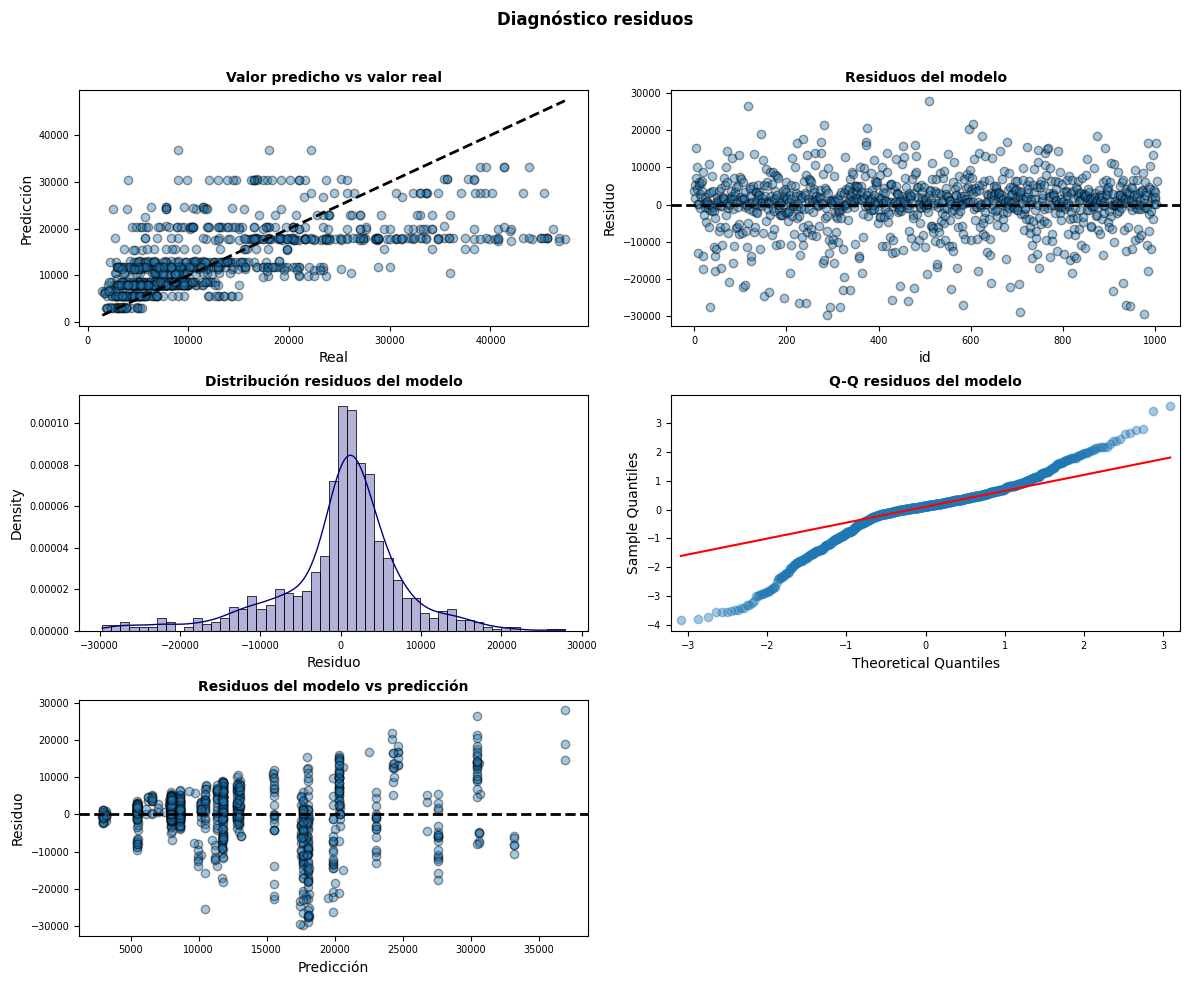

In [45]:
# Gráficos para el pronóstico de residuos

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 10))

axes[0, 0].scatter(y_train, prediccion_train, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()],
                '--', color = 'black', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    color = 'navy', #'firebrick',
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10,
                     fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train,
    fit   = True,
    line  = 'q',
    ax    = axes[1, 1],
    color = 'navy', #'firebrick',
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)


axes[2, 0].scatter(prediccion_train, residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2,1])

fig.tight_layout()
plt.subplots_adjust(top=0.9)
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");

## 6. Evaluar el desempeño del modelo


El modelo es evaluado usando el dataset de prueba para que no haya perdida  de información desde el entrenamiento del modelo.


Como primer paso, se calcula un conjunto de métricas de desempeño. Hay muchas métricas posibles utilizadas para la evaluación de modelos de regresión. En general, estas métricas son funciones del **valor residual**, o diferencia entre el valor predicho o *score* y el valor real de la etiqueta:


$$r_i = f(x_i) - y_i = \hat{y}_i - y_i$$

Algunas de las metricas más comunes son:

- **Error medio cuadrado (Mean squared error)** o MSE,  
$$MSE = \frac{1}{N} \sum_{i=1}^N (f(x_i) - y_i)^2$$

El error medio cuadrado es idéntico a la varianza de los residuos (con un ligero sesgo). Recordemos que esta métrica es la que minimiza la regresión lineal. Observe que el error cuadrático medio está en unidades del cuadrado de los valores de la etiqueta.

- **Raiz del error cuadrático medio (Root mean squared error)** o RMSE,  
$$RMSE = \sqrt{ \frac{1}{N} \sum_{i=1}^N (f(x_i) - y_i)^2}$$

Raiz del error cuadrático medio es idéntico a la desviación estándar de los residuos (de nuevo, con un ligero sesgo). El error cuadrático medio está en las mismas unidades que los valores de la etiqueta.

- **Error absoluto promedio (Mean absolute error)** o MAE,
$$MAE = \frac{1}{N} \sum_{i=1}^N |f(x_i) - y_i|$$  
donde $||$ es el operador del valor absoluto.  

Es similar en interpretación a la raiíz del error cuadrático medio. Puede encontrar esta medida más intuitiva ya que es simplemente el promedio de la magnitud de los residuos.

- **Error absoluto medio (Median absolute error)**,
$$Median\ Absolute\ Error = Median \big( \sum_{i=1}^N |f(x_i) - y_i| \big)$$   

El error absoluto medio es una medida robusta de ubicación de los residuos absolutos. *Si esta medida es significativamente diferente del error absoluto promedio, es probable que haya valores atípicos en los residuos*.


- **$R^2$** o **Coeficiente de determinación**,  
$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$  
donde,   
$SS_{res} = \sum_{i=1}^N r_i^2$, o la suma de los residuos cuadrados,   
$SS_{res} = \sum_{i=1}^N y_i^2$, o la suma de los valores de la etiqueta al cuadrado.  

En otras palabras, $R^2$ es la medida de la reducción en la suma de valores al cuadrado entre los valores de etiqueta sin procesar y los residuos.

Si el modelo no ha reducido la suma de cuadrados de las etiquetas (es un modelo inútil!), $R^2=0$.

si el modelo se ajusta perfectamente a los datos, todos $r_i= 0$, entonces $R^2=1$.


- **$R^2_{adj}$** es $R^2$ ajustado por grados de libertad en el modelo,
$$R^2_{adj} = 1 - \frac{var(r)}{var(y)} = 1 - \frac{\frac{SS_{res}}{(n - p -1)}}{\frac{SS_{tot}}{(n-1)}}$$  
donde,   
$var(r) = $ la varianza de los residuales,   
$var(y) = $ la varianza de las etiquetas,
$n = $ número de ejemplos o casos,
$p = $ numero de parametros.  

The interpretation of $R^2_{adj}$ is the same as $R^2$. In many cases there will be little difference. However if the number of parameters is significant with respect to the number of cases, $R^2$ will give an overly optimistic measure of model performance. In general, the difference between $R^2_{adj}$ and $R^2$ becomes less significant as the number of cases $n$ grows. However, even for 'big data' models there can be a significant difference if there are a large number of model parameters.   

In [46]:
# Error de test del modelo

X_test = sm.add_constant(X_test, prepend=True)
predicciones = modelo.predict(exog = X_test)

mse = mean_squared_error (y_true  = y_test, y_pred  = predicciones)
rmse = np.sqrt(mse)
MAE = mean_absolute_error (y_true  = y_test, y_pred  = predicciones)
MedAE = median_absolute_error (y_true  = y_test, y_pred  = predicciones)
r2 = r2_score (y_true  = y_test, y_pred  = predicciones)

print(f"El error MSE   de test es: {mse}")
print(f"El error RMSE  de test es: {rmse}")
print(f"El error MAE   de test es: {MAE}")
print(f"El error MedAE de test es: {MedAE}")
print(f"El R2    de test es: {r2}")

El error MSE   de test es: 49899326.741294734
El error RMSE  de test es: 7063.945550561296
El error MAE   de test es: 4868.7123468025475
El error MedAE de test es: 2856.571386902021
El R2    de test es: 0.44037518492511896


## 7. Predicción-Prueba

Primero identificamos cuáles son posibles valores para `Engine` e identificar posibles `Price` para dicho *Engine*

In [47]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

#Se agrupan todos los posibles valores de Engine
d.groupby(['Engine'])['Price'].agg(['count', 'mean','median', 'var']).head()

,count,mean,median,var
Engine,,,,
793.00,1,3588.00,3588.00,NaN
796.00,28,3274.71,3270.00,1092492.82
799.00,7,4145.14,3828.00,640212.84
814.00,12,3180.00,3150.00,554400.00
998.00,105,5570.06,4560.00,10220814.68


In [48]:
#Descripción de Engine
print(d['Engine'].describe())

count   1436.00
mean    1580.47
std      529.85
min      793.00
25%     1197.00
50%     1493.00
75%     1968.00
max     4663.00
Name: Engine, dtype: float64


In [49]:
# Se agrupa en bins de a 100 los valores de Engine y se calcula la media y mediana de precio
# para los vehiculos de este rango de Engine

#Se crea una lista de rangos de a 100, desde el valor mínimo hasta el máximo de Engine (redondeados a la centena)
bins = list(range(int(d['Engine'].min() // 100 * 100), int(d['Engine'].max() // 100 * 100) + 200, 100))

# Aplicamos pd.cut() para agrupar la variable Engine en los rangos definidos
d['range'] = pd.cut(d['Engine'], bins=bins)

# Creamos un nuevo dataframe con la nueva columna de rangos, rellenando con 0 los precios para aquellos rangos
# que no tengan ningun elemento
resultados = d.groupby('range')['Price'].agg(['mean', 'median', 'std']).fillna(0)

# Se reinicia los indices para almacenar en una nueva columna del dataframe el rango
resultados.reset_index(inplace=True)

resultados.head()

,range,mean,median,std
0,"(700, 800]",3452.67,3420.00,1036.48
1,"(800, 900]",3180.00,3150.00,744.58
2,"(900, 1000]",5766.19,4680.00,3294.77
3,"(1000, 1100]",3446.61,2700.00,1937.89
4,"(1100, 1200]",6621.09,6600.00,2114.29


In [50]:
# Se generan 2 nuevas columnas a partir del rango de Engine generado anteriormente: rango superior y rango inferior
resultados['rangoInf'] = resultados['range'].apply(lambda x: x.left)
resultados['rangoSup'] = resultados['range'].apply(lambda x: x.right)


# Se generan 2 nuevas columnas a partir la desviacion estándar
resultados['medStdInf'] = resultados['median'] - resultados['std']
resultados['medStdSup'] = resultados['median'] + resultados['std']

# Se reordenan las columnas
ordenColumnas = ['range', 'rangoInf', 'rangoSup', 'mean', 'std','medStdInf','median', 'medStdSup']
resultados = resultados.reindex(columns=ordenColumnas)

resultados.head(20)

,range,rangoInf,rangoSup,mean,std,medStdInf,median,medStdSup
0,"(700, 800]",700,800,3452.67,1036.48,2383.52,3420.00,4456.48
1,"(800, 900]",800,900,3180.00,744.58,2405.42,3150.00,3894.58
2,"(900, 1000]",900,1000,5766.19,3294.77,1385.23,4680.00,7974.77
3,"(1000, 1100]",1000,1100,3446.61,1937.89,762.11,2700.00,4637.89
4,"(1100, 1200]",1100,1200,6621.09,2114.29,4485.71,6600.00,8714.29
5,"(1200, 1300]",1200,1300,7405.21,2554.81,5245.19,7800.00,10354.81
6,"(1300, 1400]",1300,1400,11524.52,7724.84,975.16,8700.00,16424.84
7,"(1400, 1500]",1400,1500,10486.43,5972.03,3057.97,9030.00,15002.03
8,"(1500, 1600]",1500,1600,10049.83,3798.97,6701.03,10500.00,14298.97
9,"(1600, 1700]",1600,1700,18990.00,42.43,18947.57,18990.00,19032.43


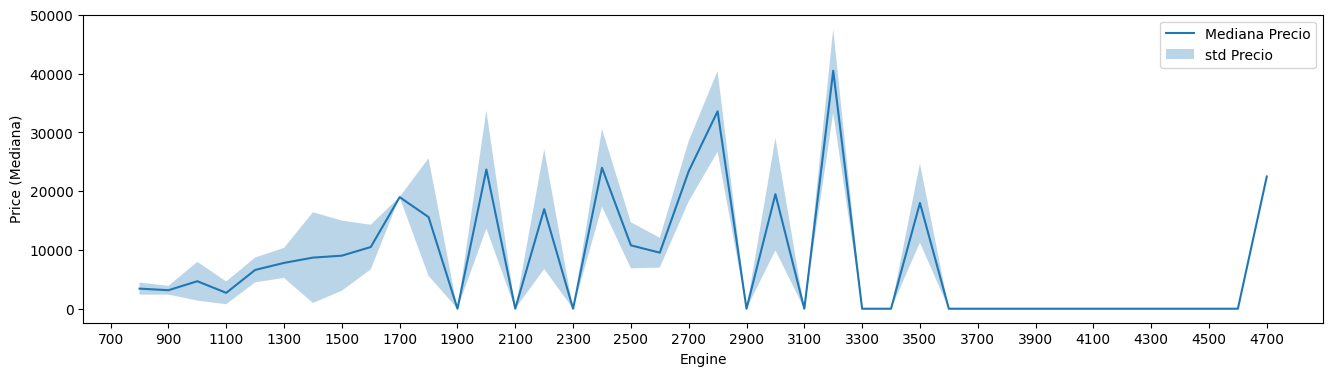

In [51]:
# Gráfica Engine vs Price

# Se crea la figura con un tamaño establecido (en pulgadas)
fig = plt.figure(figsize=(16, 4))

# Se adiciona una una gráfica a la figura creada anteriormente
ax = fig.add_subplot()

# Se crean las listas con los valores para la gráfica
x = resultados['rangoSup'].tolist()
y = resultados['median'].tolist()
std = resultados[ 'std'].tolist()


# Se grafica la línea principal
ax.plot(x, y, label='Mediana Precio')


# Se rellena el área entre la línea principal y la desviación estándar
ax.fill_between(x,
                [y_i - std_i for y_i, std_i in zip(y, std)],
                [y_i + std_i for y_i, std_i in zip(y, std)],
                alpha=0.3,
                label='std Precio')

# Se agregan títulos y etiquetas de ejes
plt.xlabel('Engine')
plt.ylabel('Price (Mediana)')

#Se le dan valores a los ejes
plt.xticks(np.arange(bins[0], bins[-1] + 1, 200))
plt.yticks(np.arange(0, 60000, 10000))

# Leyenda
ax.legend(loc="upper right")

# Mostrar la gráfica
plt.show()

### Probando el modelo

In [58]:
# Hacer predicciones sobre valores particulares

#Valor para Engine (valores de ejemplo para probar: 1000, 1600, 2600 y 3600)

engine = 3600


engine = float(engine)

# Se adiciona el valor a un array y se incluye la contante 1
v = np.array([1, engine])

#Se realiza la predicción pasando el array con el valor del Engine
prediccion = modelo.predict(exog = v)

#Se imprime el precio calculado de venta a partir del modelo
print('El precio del vehículo: {:,.0f}'.format(prediccion.item()))

El precio del vehículo: 38,206


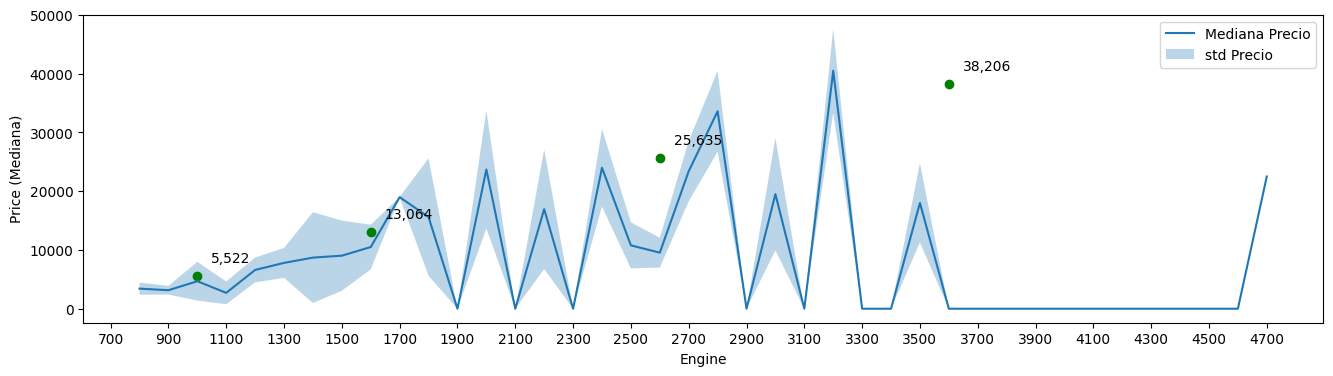

In [59]:
ax.scatter(engine, prediccion, color='Green')

ax.annotate('{:,.0f}'.format(prediccion.item()), (engine, prediccion), xytext=(10,10), textcoords='offset points')

fig

### Visualización del modelo

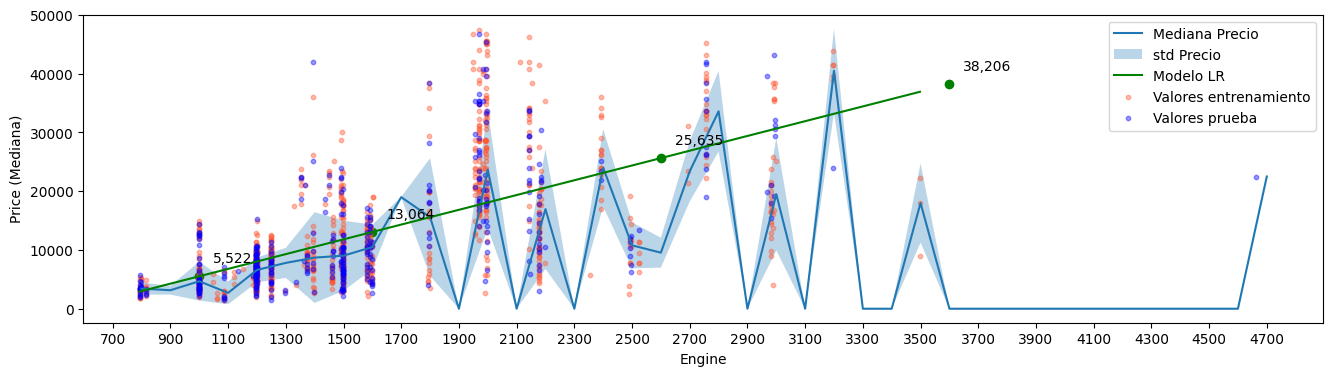

In [60]:
# Se grafica el modelo que es una función lineal de la forma y=mx+b y para el cual se definió
# una funcion previamente al inicio de este cuaderno


# Tanto b como m se obtienen del modelo entrenado (son los que muestra el model summary en la creación del modelo)
b = modelo.params['const']    #const del modelo
m = modelo.params['Engine']   #Coeficiente de Engine


# El valor de 'x' corresponde a la lista de todos los valores que puede tomar Engine (entre el mínimo y el máximo observados en entrenamiento)
x = range(int(X_train['Engine'].min()), int(X_train['Engine'].max()) + 1)


# Se gráfica la linea utilizando 'x' y la funccion y = f(m,i,b)
ax.plot(x, [f(m,i,b) for i in x], color = 'green', label='Modelo LR')


#Se adicionan a la gráfica los valores reales de entrenamiento y prueba
ax.scatter(X_train['Engine'] , y_train, s=10, alpha = 0.4, color = '#FF5733', label='Valores entrenamiento')
ax.scatter(X_test['Engine'] , y_test, s=10, alpha = 0.4, color = 'blue', label='Valores prueba')

ax.legend(loc="upper right")

fig

#### Referencias

- https://www.cienciadedatos.net/documentos/py10-regresion-lineal-python.html
- https://www.cienciadedatos.net/documentos/py06_machine_learning_python_scikitlearn.html
- https://scikit-learn.org/stable/
- https://scikit-learn.org/stable/user_guide.html\
- https://jdvelasq.github.io/courses/analitica-de-grandes-datos/index.html